In [15]:
import time
import random
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urlsplit, urlunsplit
from urllib.robotparser import RobotFileParser
from IPython.display import display


# 1. KONFIGURASI

BASE_URL = "https://itch.io/games"
ALLOWED_HOSTS = frozenset({"itch.io"})
USER_AGENT = "DM-StudentBot/1.0 (educational data mining; contact: emailkamu@kampus.ac.id)"
TIMEOUT = 20
TARGET_BARIS = 1600

DELAY_MIN = 3.0
DELAY_MAX = 6.0

# Retry 
MAX_RETRY = 5
BACKOFF_AWAL = 30  # detik


# 2. VALIDASI

def validasi_url(url: str) -> None:
    bagian = urlsplit(url)
    if bagian.scheme != "https" or bagian.hostname not in ALLOWED_HOSTS:
        raise ValueError("URL harus HTTPS dan host itch.io")


def diizinkan_robots(url: str) -> bool:
    bagian = urlsplit(url)
    robots_url = urlunsplit((bagian.scheme, bagian.netloc, "/robots.txt", "", ""))
    try:
        r = requests.get(robots_url, headers={"User-Agent": USER_AGENT}, timeout=TIMEOUT)
        if 400 <= r.status_code < 500:
            return True
        r.raise_for_status()
    except requests.RequestException:
        return False
    parser = RobotFileParser()
    parser.set_url(robots_url)
    parser.parse(r.text.splitlines())
    return parser.can_fetch(USER_AGENT, url)


# 3. AMBIL HTML DENGAN RETRY & BACKOFF

def ambil_html(url: str) -> str:
    validasi_url(url)
    if not diizinkan_robots(url):
        raise PermissionError("Robots.txt melarang pengambilan")

    for percobaan in range(1, MAX_RETRY + 1):
        try:
            r = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=TIMEOUT)

            if r.status_code == 429:
                tunggu = BACKOFF_AWAL * percobaan + random.uniform(0, 10)
                print(f"    [429] rate limit, tunggu {tunggu:.0f}s (percobaan {percobaan}/{MAX_RETRY})")
                time.sleep(tunggu)
                continue

            r.raise_for_status()

            if "text/html" not in r.headers.get("Content-Type", "").lower():
                raise ValueError("Respons bukan HTML")

            # Delay acak setelah sukses
            jeda = random.uniform(DELAY_MIN, DELAY_MAX)
            time.sleep(jeda)
            return r.text

        except requests.RequestException as e:
            if percobaan == MAX_RETRY:
                raise
            tunggu = BACKOFF_AWAL * percobaan
            print(f"    [error] {e}, tunggu {tunggu}s")
            time.sleep(tunggu)

    raise RuntimeError("Gagal setelah semua percobaan")


# 4. PARSING GAME CELL

def parse_game_cell(cell) -> dict | None:
    title_el = cell.find("div", class_="game_title")
    if not title_el:
        return None
    title = title_el.get_text(strip=True)

    author_el = cell.find("div", class_="game_author")
    author = author_el.get_text(strip=True) if author_el else None

    genre_el = cell.find("div", class_="game_genre")
    genre = genre_el.get_text(strip=True) if genre_el else "Unknown"

    text_el = cell.find("div", class_="game_text")
    text = text_el.get_text(strip=True) if text_el else None

    # --- Harga ---
    # Default 0.0 = gratis (termasuk "name your own price")
    price = 0.0
    price_el = cell.find("div", class_="price_value")
    if price_el:
        m = re.search(r"\$([\d.]+)", price_el.get_text(strip=True))
        if m:
            price = float(m.group(1))

    return {
        "title": title,
        "author": author,
        "genre": genre,
        "description": text,
        "price": price,
    }


# 5. SCRAPING MULTI-HALAMAN

def scrape_itch_io(target: int = TARGET_BARIS) -> pd.DataFrame:
    print(f"Target: {target} baris")
    semua = []
    page = 1

    while len(semua) < target:
        url = f"{BASE_URL}?page={page}"
        print(f"  Halaman {page} ... (total sementara: {len(semua)})")

        try:
            html = ambil_html(url)
        except Exception as e:
            print(f"    gagal total: {e}")
            break

        soup = BeautifulSoup(html, "html.parser")
        cells = soup.find_all("div", class_="game_cell")
        print(f"    {len(cells)} game ditemukan")

        if not cells:
            print("    (tidak ada game, berhenti)")
            break

        for cell in cells:
            parsed = parse_game_cell(cell)
            if parsed:
                semua.append(parsed)

        page += 1
        if page > 100:
            break

    df = pd.DataFrame(semua)
    print(f"\n[OK] Total: {len(df)} baris")
    return df


# 6. EKSEKUSI

if __name__ == "__main__":
    try:
        df = scrape_itch_io()
        display(df.head(10))
        print(f"\nShape: {df.shape}")
        print(f"Kolom: {list(df.columns)}")

        df.to_csv("itchio_games_v2.csv", index=False)
        print("[OK] Tersimpan sebagai itchio_games_v2.csv")

    except Exception as e:
        print(f"Error: {e}")

Target: 1600 baris
  Halaman 1 ... (total sementara: 0)
    36 game ditemukan
  Halaman 2 ... (total sementara: 36)
    36 game ditemukan
  Halaman 3 ... (total sementara: 72)
    36 game ditemukan
  Halaman 4 ... (total sementara: 108)
    36 game ditemukan
  Halaman 5 ... (total sementara: 144)
    36 game ditemukan
  Halaman 6 ... (total sementara: 180)
    36 game ditemukan
  Halaman 7 ... (total sementara: 216)
    36 game ditemukan
  Halaman 8 ... (total sementara: 252)
    36 game ditemukan
  Halaman 9 ... (total sementara: 288)
    36 game ditemukan
  Halaman 10 ... (total sementara: 324)
    36 game ditemukan
  Halaman 11 ... (total sementara: 360)
    36 game ditemukan
  Halaman 12 ... (total sementara: 396)
    36 game ditemukan
  Halaman 13 ... (total sementara: 432)
    36 game ditemukan
  Halaman 14 ... (total sementara: 468)
    36 game ditemukan
  Halaman 15 ... (total sementara: 504)
    36 game ditemukan
  Halaman 16 ... (total sementara: 540)
    36 game ditemukan
  

,title,author,genre,description,price
0,The No Jumpscare Show,Polypaw,Adventure,A 100% jumpscare-free experience :),0.00
1,Not My Dad - DEMO,Escapebox,Adventure,Short Horror Game,0.00
2,MANDATO$1.94-35%,SolitaryStudios,Simulation,A horror story about corruption,1.94
3,GET UPSTAIRS,JoeTheItchPro,Survival,Turn the lights off.,0.00
4,FailRooms,LeonnCamayo,Adventure,Failrooms: A realistic comedy about the terrib...,0.00
5,Death Loop [A Danganronpa-inspired Game],Hopeful Light,Visual Novel,Inspired by Danganronpa and other death games,0.00
6,771 DEMO,a1esska,Adventure,A psychological horror game in the walking sim...,0.00
7,The Delivery Guy,Unfall Games,Adventure,It shouldâve been a normal deliveryâ¦,0.00
8,CLIMB,Kyle Horwood,Unknown,You've fallen... can you get back out?,0.00
9,Twilight Observer,WhiteScar Studios,Interactive Fiction,An adventure game where choices matter,0.00



Shape: (1620, 5)
Kolom: ['title', 'author', 'genre', 'description', 'price']
[OK] Tersimpan sebagai itchio_games_v2.csv


1. PEMAHAMAN DATASET

    5 Baris Pertama    


,title,author,genre,description,price
0,The No Jumpscare Show,Polypaw,Adventure,A 100% jumpscare-free experience :),0.00
1,Not My Dad - DEMO,Escapebox,Adventure,Short Horror Game,0.00
2,MANDATO$1.94-35%,SolitaryStudios,Simulation,A horror story about corruption,1.94
3,GET UPSTAIRS,JoeTheItchPro,Survival,Turn the lights off.,0.00
4,FailRooms,LeonnCamayo,Adventure,Failrooms: A realistic comedy about the terrib...,0.00



    Shape    
Jumlah baris: 1620
Jumlah kolom: 5

    Info Umum    
<class 'pandas.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        1620 non-null   str    
 1   author       1620 non-null   str    
 2   genre        1620 non-null   str    
 3   description  1529 non-null   str    
 4   price        1620 non-null   float64
dtypes: float64(1), str(4)
memory usage: 63.4 KB

    Tipe Data    
title              str
author             str
genre              str
description        str
price          float64
dtype: object

--- Ide    ntifikasi Tipe Atribut ---
  title           -> Nominal (teks, 1620 unik)
  author          -> Nominal (teks, 1303 unik)
  genre           -> Nominal (kategorikal, 18 unik)
  description     -> Nominal (teks, 1517 unik)
  price           -> Numerik (kontinu)
2. ANALISIS STATISTIK & KUALITAS DATA

    Statistik Deskriptif (Numerik) 

,mean,median,mode,std,min,max
price,0.993926,0.0,0.0,3.667102,0.0,30.0



    Frekuensi Genre (Top 15)    


genre
Visual Novel           588
Adventure              194
Simulation             145
Unknown                103
Role Playing            94
Action                  85
Puzzle                  84
Platformer              84
Strategy                51
Interactive Fiction     50
Survival                38
Shooter                 29
Fighting                20
Rhythm                  17
Racing                  16
Name: count, dtype: int64

... (2 outputs left out)


    Missing Values    


,jumlah_hilang,persentase
description,91,5.62



    Deteksi Outlier (Metode IQR)    
  price: 173 outlier (batas: 0.00 - 0.00)
3. VISUALISASI UNIVARIAT


C:\Users\airal\AppData\Local\Temp\ipykernel_10688\517376048.py:115: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df["price"].dropna(), vert=False)


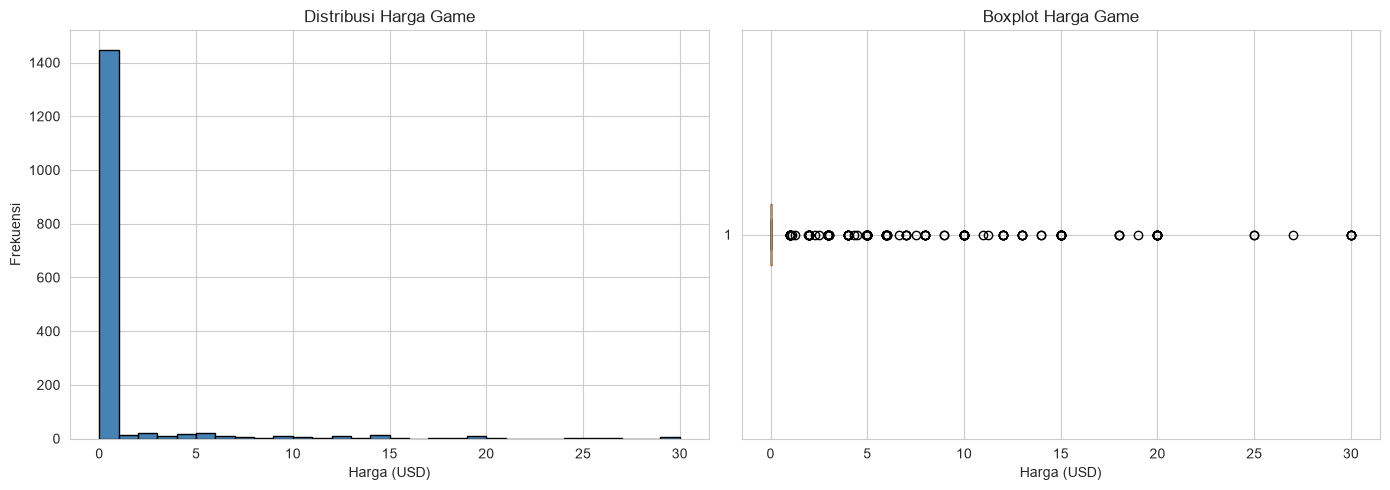


Interpretasi:
  Game gratis: 1447 (89.3%)
  Game berbayar: 173 (10.7%)
  Harga rata-rata (berbayar saja): $9.31
  Harga maksimum: $30.00


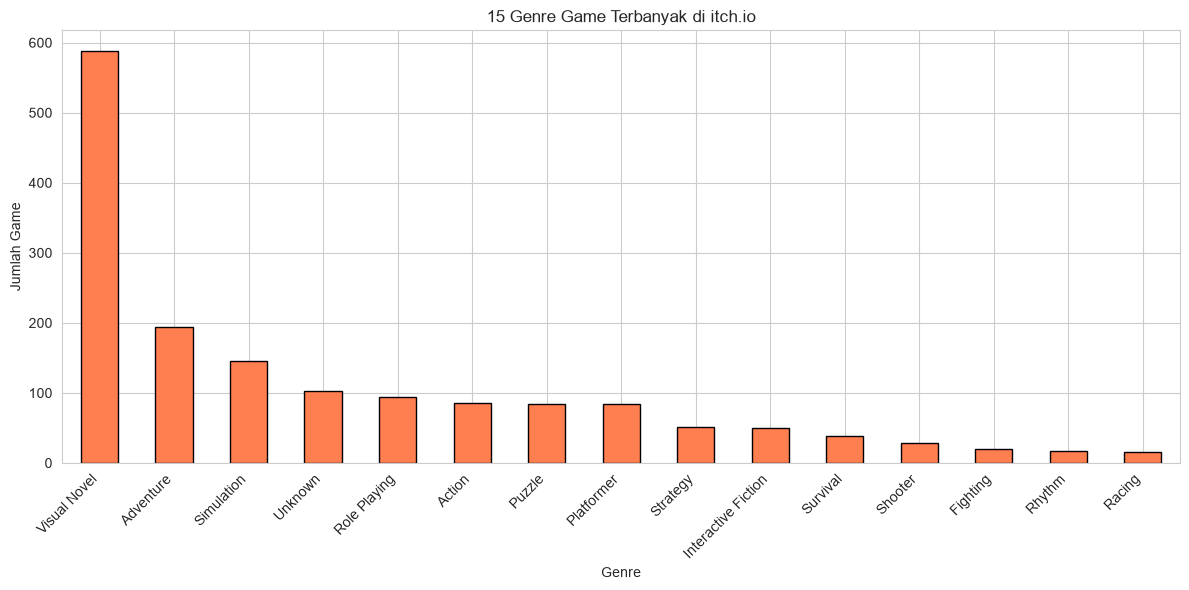


Interpretasi: Genre visual-novel dan puzzle mendominasi itch.io,
menunjukkan preferensi komunitas indie terhadap genre naratif dan casual.
4. VISUALISASI BIVARIAT


C:\Users\airal\AppData\Local\Temp\ipykernel_10688\517376048.py:155: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top, x="genre", y="price", palette="Set3")


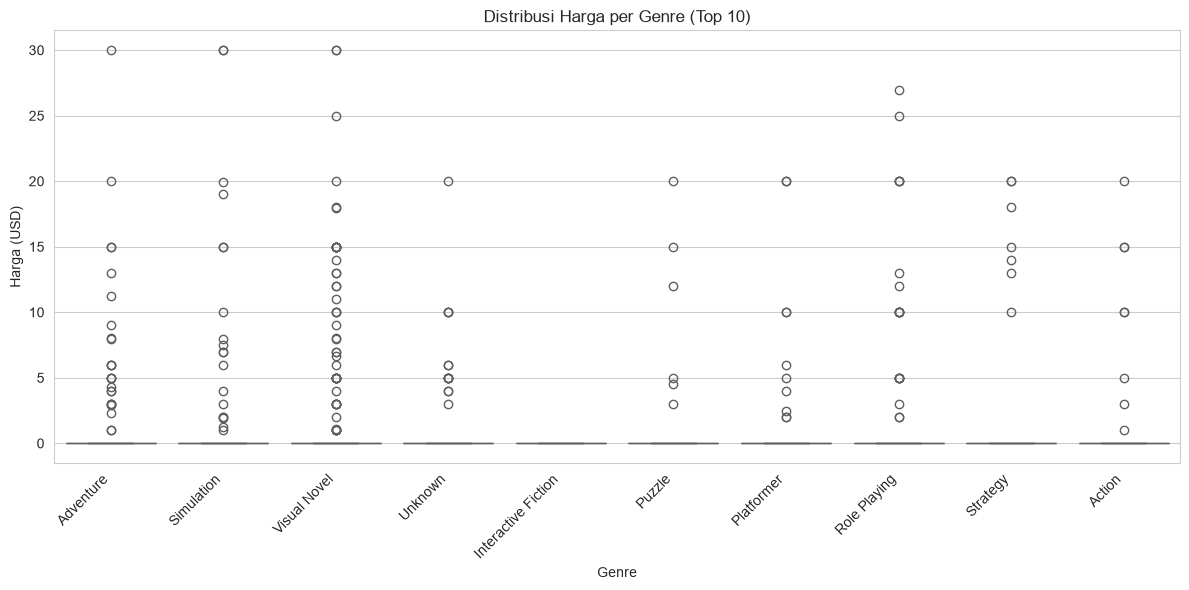

Interpretasi: Beberapa genre punya median harga lebih tinggi dari yang lain.
Genre dengan box lebih pendek berarti harganya lebih konsisten.


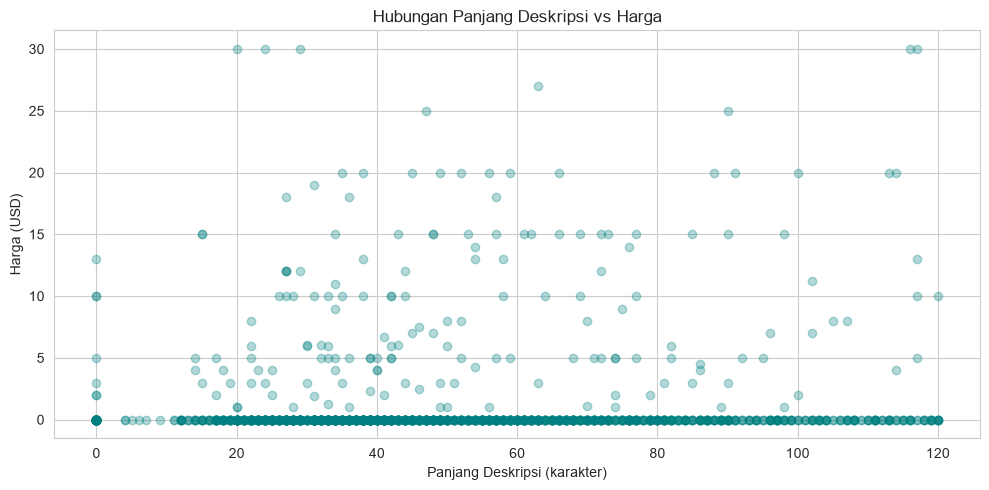

Interpretasi: Kalau titik tersebar acak, tidak ada hubungan antara
panjang deskripsi dan harga game.


In [18]:
# EDA 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


# 1. IMPORT & PEMAHAMAN DATASET

df = pd.read_csv("itchio_games_v2.csv")

print("1. PEMAHAMAN DATASET")

print("\n    5 Baris Pertama    ")
display(df.head())

print(f"\n    Shape    ")
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

print("\n    Info Umum    ")
df.info()

print("\n    Tipe Data    ")
print(df.dtypes)

print("\n--- Ide    ntifikasi Tipe Atribut ---")
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        tipe = "Numerik (kontinu)"
    else:
        n_unique = df[col].nunique()
        if n_unique <= 20:
            tipe = f"Nominal (kategorikal, {n_unique} unik)"
        else:
            tipe = f"Nominal (teks, {n_unique} unik)"
    print(f"  {col:15s} -> {tipe}")


# 2. ANALISIS STATISTIK & KUALITAS DATA

print("2. ANALISIS STATISTIK & KUALITAS DATA")

print("\n    Statistik Deskriptif (Numerik)    ")
numerik = df.select_dtypes(include=[np.number])
if not numerik.empty:
    stats = pd.DataFrame({
        "mean": numerik.mean(),
        "median": numerik.median(),
        "std": numerik.std(),
        "min": numerik.min(),
        "max": numerik.max(),
    })
    
    stats["mode"] = [
        numerik[c].mode().iloc[0] if not numerik[c].mode().empty else np.nan
        for c in numerik.columns
    ]
    stats = stats[["mean", "median", "mode", "std", "min", "max"]]
    display(stats)
else:
    print("Tidak ada kolom numerik.")

# Frekuensi kategorikal
print("\n    Frekuensi Genre (Top 15)    ")
display(df["genre"].value_counts().head(15))

print("\n    Frekuensi Author (Top 10)    ")
display(df["author"].value_counts().head(10))

# Missing values
print("\n    Missing Values    ")
missing = pd.DataFrame({
    "jumlah_hilang": df.isnull().sum(),
    "persentase": (df.isnull().sum() / len(df) * 100).round(2),
})
if missing["jumlah_hilang"].sum() > 0:
    display(missing[missing["jumlah_hilang"] > 0])
else:
    print("Tidak ada missing value")

# Deteksi outlier 
print("\n    Deteksi Outlier (Metode IQR)    ")
for col in numerik.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = df[(df[col] < lower) | (df[col] > upper)]
    print(f"  {col}: {len(outlier)} outlier (batas: {lower:.2f} - {upper:.2f})")


# 3. VISUALISASI UNIVARIAT

print("3. VISUALISASI UNIVARIAT")

# --- Distribusi Price ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram price
axes[0].hist(df["price"].dropna(), bins=30, color="steelblue", edgecolor="black")
axes[0].set_title("Distribusi Harga Game")
axes[0].set_xlabel("Harga (USD)")
axes[0].set_ylabel("Frekuensi")

# Boxplot price
axes[1].boxplot(df["price"].dropna(), vert=False)
axes[1].set_title("Boxplot Harga Game")
axes[1].set_xlabel("Harga (USD)")

plt.tight_layout()
plt.show()

# Statistik berapa persen gratis
gratis = (df["price"] == 0).sum()
berbayar = (df["price"] > 0).sum()
print(f"\nInterpretasi:")
print(f"  Game gratis: {gratis} ({gratis/len(df)*100:.1f}%)")
print(f"  Game berbayar: {berbayar} ({berbayar/len(df)*100:.1f}%)")
print(f"  Harga rata-rata (berbayar saja): ${df[df['price']>0]['price'].mean():.2f}")
print(f"  Harga maksimum: ${df['price'].max():.2f}")

# Bar chart genre 
top_genre = df["genre"].value_counts().head(15)
plt.figure(figsize=(12, 6))
top_genre.plot(kind="bar", color="coral", edgecolor="black")
plt.title("15 Genre Game Terbanyak di itch.io")
plt.xlabel("Genre")
plt.ylabel("Jumlah Game")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nInterpretasi: Genre visual-novel dan puzzle mendominasi itch.io,")
print("menunjukkan preferensi komunitas indie terhadap genre naratif dan casual.")


# 4. VISUALISASI BIVARIAT

print("4. VISUALISASI BIVARIAT")

# Boxplot price per genre (top 10)
top10 = df["genre"].value_counts().head(10).index
df_top = df[df["genre"].isin(top10)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x="genre", y="price", palette="Set3")
plt.title("Distribusi Harga per Genre (Top 10)")
plt.xlabel("Genre")
plt.ylabel("Harga (USD)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Interpretasi: Beberapa genre punya median harga lebih tinggi dari yang lain.")
print("Genre dengan box lebih pendek berarti harganya lebih konsisten.")

# Correlation heatmap 
numerik_kolom = df.select_dtypes(include=[np.number]).columns.tolist()
if len(numerik_kolom) >= 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(df[numerik_kolom].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
    print("Interpretasi: Heatmap menunjukkan korelasi antar atribut numerik.")

# Scatter: panjang deskripsi vs harga
df["desc_len"] = df["description"].fillna("").astype(str).str.len()

plt.figure(figsize=(10, 5))
plt.scatter(df["desc_len"], df["price"], alpha=0.3, color="teal")
plt.title("Hubungan Panjang Deskripsi vs Harga")
plt.xlabel("Panjang Deskripsi (karakter)")
plt.ylabel("Harga (USD)")
plt.tight_layout()
plt.show()

print("Interpretasi: Kalau titik tersebar acak, tidak ada hubungan antara")
print("panjang deskripsi dan harga game.")

In [19]:
gratis = (df["price"] == 0).sum()
berbayar = (df["price"] > 0).sum()

print(f"Gratis: {gratis} ({gratis/len(df)*100:.1f}%)")
print(f"Berbayar: {berbayar} ({berbayar/len(df)*100:.1f}%)")
print(f"\nRata-rata harga game BERBAYAR saja: ${df[df['price']>0]['price'].mean():.2f}")
print(f"Median harga game BERBAYAR saja: ${df[df['price']>0]['price'].median():.2f}")

Gratis: 1447 (89.3%)
Berbayar: 173 (10.7%)

Rata-rata harga game BERBAYAR saja: $9.31
Median harga game BERBAYAR saja: $6.99
